This notebook accompanies [10-quantum-dynamics](https://xing-phys.github.io/ai-for-physics/10-quantum-dynamics.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Learning quantum dynamics without losing the physics 

A ground state answers what a system prefers at equilibrium. A dynamical calculation asks how it responds when a field is switched, two clouds collide, or a quantum simulator is prepared far from equilibrium. Interference, conserved quantities, and spreading entanglement all matter. A neural state can adapt its parameters in time, but an accurate ground-state optimizer is not automatically an accurate dynamical solver. Energy minimization has a direction toward a low-energy state; real-time evolution rotates amplitudes coherently and can amplify small phase errors.

We begin with exact unitary evolution, derive imaginary-time filtering, and then project both equations onto a variational family. This makes the relation between stochastic reconfiguration and time-dependent variational Monte Carlo explicit. We will distinguish errors caused by the ansatz, Monte Carlo sampling, and the differential-equation integrator.

::: {.callout-note title="Learning goals and prerequisites"}
Read [VMC](09-variational-monte-carlo.ipynb), especially the logarithmic derivatives, covariance metric, and force. We use matrix exponentials and first-order differential equations, which we introduce as needed. You should finish able to derive real- and imaginary-time parameter equations, check their signs and factors, calculate a quench observable, and design diagnostics for an approximate trajectory. The next chapter, [Fermions and mixed states](11-fermions-and-mixed-states.ipynb), extends these questions to electronic structure and dissipation.
:::

## Exact dynamics, quenches, and observables 

For a closed system, the Schrödinger equation is

$$
i\hbar\frac{d}{dt}|\psi(t)\rangle=H(t)|\psi(t)\rangle.
$$ 

For a time-independent Hermitian Hamiltonian with eigenstates $|n\rangle$, expansion of the initial state gives

$$
|\psi(t)\rangle=\sum_n c_n e^{-iE_nt/\hbar}|n\rangle.
$$

Each coefficient rotates in the complex plane. Its magnitude is unchanged, so normalization is conserved. The mean energy is also conserved when $H$ is time independent. More generally, differentiating $\langle A\rangle$ yields

$$
\frac{d}{dt}\langle A\rangle
=\frac{i}{\hbar}\langle[H,A]\rangle
+\left\langle\frac{\partial A}{\partial t}\right\rangle.
$$

The two terms from differentiating bra and ket produce the commutator $[H,A]=HA-AH$. If $[H,A]=0$ and $A$ has no explicit time dependence, the quantity is conserved. These exact properties are strong implementation diagnostics, although preserving a few conserved quantities does not guarantee the entire state is accurate.

A *quench* means preparing a state associated with one Hamiltonian and then evolving with another. For a single spin, start in $|\uparrow\rangle$ and evolve with $H=(\hbar\Omega/2)\sigma^x$. Because $(\sigma^x)^2=I$, separating even and odd powers of the exponential gives

$$
e^{-i\Omega t\sigma^x/2}
=\cos(\Omega t/2)I-i\sin(\Omega t/2)\sigma^x.
$$

Thus $|\psi(t)\rangle=\cos(\Omega t/2)|\uparrow\rangle-i\sin(\Omega t/2)|\downarrow\rangle$ and $\langle\sigma^z\rangle=\cos\Omega t$. The $-i$ relative phase is necessary. A positive real wavefunction cannot reproduce this trajectory, even though it can reproduce its instantaneous $z$ probabilities at selected times. This is a minimal test of whether a dynamical ansatz has enough phase freedom.

## Imaginary time is a filter, not laboratory time 

Replace real time by $t=-i\tau$ in the formal propagator. The unnormalized state satisfies

$$
\hbar\partial_\tau|\widetilde\psi\rangle=-H|\widetilde\psi\rangle,
\qquad |\widetilde\psi(\tau)\rangle=e^{-\tau H/\hbar}|\psi(0)\rangle.
$$

Its eigenstate coefficients become $c_ne^{-\tau E_n/\hbar}$. Relative to a ground-state component, an excited component decays as $e^{-\tau(E_n-E_0)/\hbar}$. Ground-state filtering requires nonzero initial overlap with the ground space. If a symmetry sector forbids that overlap, imaginary time finds the lowest accessible state instead. Small gaps imply slow filtering, and degeneracy leaves the initial relative weights inside the ground space undetermined.

Normalize at each time. Differentiating the norm shows that the normalized equation is

$$
\hbar\partial_\tau|\psi\rangle=-(H-E)|\psi\rangle,
\qquad E=\langle\psi|H|\psi\rangle.
$$ 

Indeed, the derivative of the squared norm is $-2\langle H-E\rangle/\hbar=0$. For a fixed Hamiltonian,

$$
\frac{dE}{d\tau}=-\frac{2}{\hbar}
\big(\langle H^2\rangle-E^2\big)\leq0.
$$ 

This follows by differentiating the energy and inserting the normalized equation on both sides. The variance is nonnegative. Imaginary time therefore lowers energy until an eigenstate is reached, subject to the accessible subspace. It is an optimization construction, not a dissipative laboratory process and not the same as a thermal density matrix at inverse temperature $\beta$. Thermal purification will require a related but distinct construction.

## Tangent-space projection with real parameters 

A trial family $|\psi_\theta\rangle$ describes only a small surface inside Hilbert space. A general exact time derivative points partly outside it. The time-dependent variational principle (TDVP) replaces that derivative by an allowed tangent vector. Different variational principles can agree on a complex tangent space and differ on a restricted real one, so we state the choice explicitly.

Let $\theta_k$ be real, define the projected derivatives $|D_k\psi\rangle$ from the VMC chapter, and use the phase convention that removes the component parallel to the state. The physical real-time target in this projective description is

$$
|v\rangle=-\frac{i}{\hbar}(H-E)|\psi\rangle.
$$

The omitted component contributes only the overall dynamical phase. McLachlan's least-squares prescription minimizes

$$
\mathcal R^2=\left\|\sum_k\dot\theta_k|D_k\psi\rangle-|v\rangle\right\|^2
$$

over real $\dot\theta$. Expanding this norm gives a quadratic form in $\dot\theta$. Its derivative is zero when

$$
\sum_l S_{kl}\dot\theta_l
=\frac{1}{\hbar}\operatorname{Im}C_k,
\qquad
C_k=\langle\Delta O_k^*\Delta E_{\mathrm{loc}}\rangle.
$$ 

The sign follows from $\operatorname{Re}(-iC)=\operatorname{Im}C$. The same calculation for normalized imaginary time gives

$$
\sum_l S_{kl}\frac{d\theta_l}{d\tau}
=-\frac{1}{\hbar}\operatorname{Re}C_k.
$$ 

This is precisely the differential version of SR. With exact expectations, a nonsingular positive metric, and a fixed Hamiltonian, the projected imaginary-time energy derivative is $-2F^TS^{-1}F/\hbar\leq0$. A positive diagonal shift replaces the inverse by $(S+\lambda I)^{-1}$ and retains this nonpositive derivative, even when $\lambda>0$ varies along the trajectory. It changes the projected path and speed. Finite numerical steps and sampling noise can spoil observed monotonicity.

The real-time equation contains a cautionary example. If both $H$ and the trial amplitudes are real, and the parameters alter only real amplitudes, then $C$ is real and the right-hand side vanishes. The least-squares dynamics can freeze because the required imaginary direction is missing. It has not discovered that the physical system is static. The single-spin quench above demonstrates the failure directly.

For a restricted real tangent space, this McLachlan flow need not conserve the variational energy exactly. Its energy derivative is $2\operatorname{Re}C^T S^{-1}\operatorname{Im}C/\hbar$, which is not generally zero. A symplectic action-based formulation has a different geometric matrix for real coordinates. One should not transfer conservation claims between these formulations without checking their assumptions.

## Complex analytic parameters and conservation 

There is a useful special case. Suppose the *unnormalized* amplitude depends holomorphically on complex parameters $z_k$: it depends on $z_k$ and not independently on $z_k^*$. The tangent space is then closed under multiplication by $i$, before the usual projective removal of normalization and phase. Complex least-squares projection gives

$$
\sum_l\mathcal S_{kl}\dot z_l=-\frac{i}{\hbar}C_k,
\qquad
\mathcal S_{kl}=\langle\Delta O_k^*\Delta O_l\rangle,
\quad O_k=\partial_{z_k}\log\widetilde\psi.
$$ 

Now $\mathcal S$ is Hermitian, not its elementwise real part. Imaginary time replaces $-i$ by $-1$. With exact averages and an appropriate inverse on the nonredundant tangent space, real-time energy is conserved for time-independent $H$. To verify this, use $dE/dt=2\operatorname{Re}(\dot z^\dagger C)$ and insert $\dot z=-i\mathcal S^{-1}C/\hbar$. The scalar $C^\dagger\mathcal S^{-1}C$ is real, so the real part of $iC^\dagger\mathcal S^{-1}C/\hbar$ is zero.

This conservation statement does not mean the approximate trajectory is exact. It can move on an incorrect constant-energy surface. It also assumes a differentiable analytic parametrization and compatible tangent space. Separate magnitude and phase networks, absolute values, conjugations, and many normalization operations can make a parameter map nonholomorphic. For such models use the fully real-coordinate derivation or derive the intended variational principle directly. Declaring parameters complex in software does not establish holomorphicity.

## Residuals and the three sources of dynamical error 

The least-squares residual measures the instantaneous part of the exact derivative that the ansatz misses. For real coordinates, let $b=\operatorname{Im}C/\hbar$ and assume an invertible $S$. The minimized squared residual is

$$
\mathcal R_{\min}^2=\frac{\operatorname{Var}(H)}{\hbar^2}-b^TS^{-1}b.
$$ 

Expand the quadratic norm, insert $S\dot\theta=b$, and subtract the fitted tangent component to obtain this result. A negative estimate from Monte Carlo indicates inconsistent noise or numerical error; the exact squared norm is nonnegative. Regularization changes the minimizing equation, so use the actual residual rather than applying the unregularized expression blindly.

With a consistent restored global phase, write an approximate trajectory's Schrödinger residual as $|R(t)\rangle=i\hbar|\dot\phi\rangle-H|\phi\rangle$. Variation of constants and unitarity imply a norm-error bound of the form

$$
\|\phi(T)-\psi(T)\|
\leq\|\phi(0)-\psi(0)\|+
\frac1\hbar\int_0^T\|R(t)\|\,dt.
$$

To see the mechanism, evolve the difference backward with the exact unitary propagator. Its derivative is driven only by the residual; integrate and apply the triangle inequality. The bound is often loose but explains why small persistent local errors can accumulate. A sampled residual estimate is not automatically a rigorous bound unless its statistical and support uncertainties are controlled.

There are three practical errors. First, the *representation/projection error* persists even with exact integrals and infinitesimal steps. Second, the metric and force are estimated from samples; ill-conditioned directions amplify that noise. Third, an ordinary differential-equation solver approximates the parameter trajectory with finite time steps. Reduce the time step at fixed high sample count to test integration; increase the samples at a converged time step to test noise; enlarge or alter the ansatz to test projection. Varying all three at once makes the source of improvement hard to interpret.

Forward Euler uses $\theta(t+\delta t)=\theta(t)+\delta t\,v(\theta,t)$ and has accumulated error of first order in $\delta t$ under regularity assumptions. A classical fourth-order Runge–Kutta method evaluates intermediate slopes and combines them as $(k_1+2k_2+2k_3+k_4)/6$. Its formal higher order assumes sufficiently smooth, consistently evaluated slopes. Monte Carlo noise and reusing inconsistent samples can destroy that asymptotic behavior. Adaptive step control based only on integrator error can miss ansatz error entirely.

## An executable quench benchmark 

We evolve four interacting spins exactly after switching on a transverse field. The code compares a fourth-order integrator with spectral evolution, monitors energy and norm, and plots magnetization and bipartite entropy. This benchmark is small enough to be exact and rich enough to exhibit entanglement generation. A neural TDVP implementation should reproduce it before attempting a larger lattice.

Maximum state error: 2.03e-07


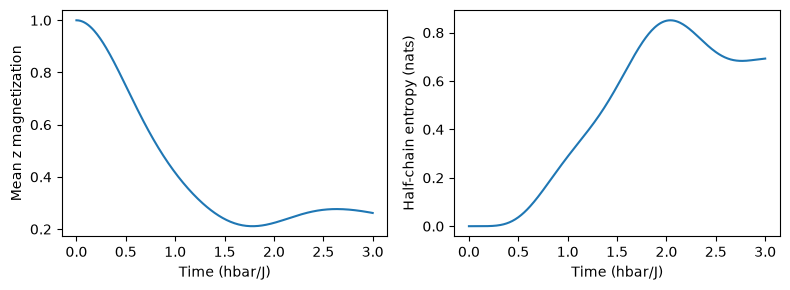

In [1]:
import numpy as np
import matplotlib.pyplot as plt
N, J, h = 4, 1.0, 0.8
sx = np.array([[0., 1.], [1., 0.]])
sz = np.diag([1., -1.])
def at_site(op, site):
    result = np.array([[1.]])
    for j in range(N):
        result = np.kron(result, op if j == site else np.eye(2))
    return result
X = [at_site(sx, j) for j in range(N)]
Z = [at_site(sz, j) for j in range(N)]
H = -J*sum(Z[j] @ Z[j+1] for j in range(N-1)) - h*sum(X)
M = sum(Z)/N
eigenvalues, eigenvectors = np.linalg.eigh(H)
initial = np.zeros(2**N, complex); initial[0] = 1.0
coefficients = eigenvectors.conj().T @ initial
dt, steps = 0.01, 300
times = np.arange(steps+1)*dt
state = initial.copy()
magnetization, entropy, errors = [], [], []
energy0 = np.vdot(initial, H @ initial).real
for step, t in enumerate(times):
    reference = eigenvectors @ (np.exp(-1j*eigenvalues*t)*coefficients)
    errors.append(np.linalg.norm(state-reference))
    magnetization.append(np.vdot(reference, M @ reference).real)
    singular = np.linalg.svd(reference.reshape(4, 4), compute_uv=False)
    weights = singular**2
    weights = weights[weights > 1e-14]
    entropy.append(-np.sum(weights*np.log(weights)))
    assert abs(np.vdot(state, H @ state).real-energy0) < 1e-6
    assert abs(np.vdot(state, state).real-1) < 1e-6
    if step < steps:
        rhs = lambda y: -1j*(H @ y)
        k1 = rhs(state)
        k2 = rhs(state+dt*k1/2)
        k3 = rhs(state+dt*k2/2)
        k4 = rhs(state+dt*k3)
        state += dt*(k1+2*k2+2*k3+k4)/6
assert max(errors) < 1e-5
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(times, magnetization)
axes[0].set(xlabel="Time (hbar/J)", ylabel="Mean z magnetization")
axes[1].plot(times, entropy)
axes[1].set(xlabel="Time (hbar/J)", ylabel="Half-chain entropy (nats)")
fig.tight_layout()
print(f"Maximum state error: {max(errors):.2e}")
plt.show()

The Hamiltonian is open rather than periodic, and the initial all-up state is not its post-quench ground state. Entropy starts at zero because the state is a product. The finite system may show recurrences; one should not interpret a short four-spin trace as evidence for thermodynamic equilibration. Repeating at larger sizes and comparing local observables is necessary to separate finite-size effects from a many-body mechanism.

## Alternatives to differential TDVP 

One alternative fits a new state after each short propagator step. If a target is $|\chi\rangle\approx(1-i\delta tH/\hbar)|\psi_\theta\rangle$, optimize parameters $\theta'$ to maximize normalized overlap with $\chi$. This trades a noisy linear differential solve for an optimization problem at every step. The short-time propagator and incomplete fitting introduce separate biases. Projecting a nonunitary first-order step repeatedly does not make the evolution exactly unitary.

Another approach gives time itself to the network: $\psi_\theta(s,t)$. One time-independent parameter set represents an entire interval. A residual objective penalizes $i\hbar\partial_t\psi_\theta-H\psi_\theta$ together with the initial condition. This resembles physics-informed learning, but the wavefunction normalization, sampling distribution, and phase gauge need explicit treatment. A small residual at finitely many sampled times does not guarantee accuracy at all times, and extrapolation outside the trained interval requires independent evidence. Explicitly time-dependent NQS have been explored for interacting spin dynamics [@q-vandewalle2024].

Tensor-network time evolution offers a competing strategy with controlled truncations tied to Schmidt spectra. Krylov propagation approximates a short-time evolved state in the subspace generated by $|\psi\rangle,H|\psi\rangle,H^2|\psi\rangle,\ldots$; its subspace dimension and time step must be converged to control error. Semiclassical approximations evolve reduced classical variables and can be accurate in suitable large-spin or weak-correlation regimes. Quantum simulators evolve the physical state directly but introduce measurement and device errors. Choosing among them is a question about the observable, regime, dimension, and accessible error diagnostics.

## Research bridge: what a long-time claim must establish 

Carleo and Troyer demonstrated neural variational dynamics alongside ground-state calculations [@q-carleo2017]. Schmitt and Heyl developed stabilization strategies and studied two-dimensional Ising quenches [@q-schmitt2020]. Their benchmarks show useful capabilities in specified regimes; they do not establish unrestricted long-time accuracy for every interacting system. Explicit-time architectures pursue a different compromise between optimization and temporal integration [@q-vandewalle2024]. Open-system variational dynamics adds a further layer because the represented object is a density matrix or measurement distribution [@q-reh2021], as developed next.

To read such papers critically, identify which quantity is compared with a trusted solver, for how long, at which sizes, and with what sampling and variational checks. Agreement in magnetization can coexist with larger errors in entanglement or rare correlations. Energy drift is a warning, but zero drift is not a full accuracy certificate. A useful frontier question is whether one can predict the reliable time horizon from accessible residuals and sampling diagnostics before the answer is known. That would turn an expressive ansatz into a more dependable scientific instrument.

## Exercises and selected solutions 

1. Derive $d\langle H\rangle/dt=\langle\partial_tH\rangle$ for an explicitly time-dependent Hamiltonian. Why is energy drift expected during a ramp?
2. For an initial superposition $a|0\rangle+b|1\rangle$ of two energy eigenstates with gap $\Delta$, find the ratio of excited to ground probabilities after normalized imaginary time $\tau$.
3. Derive both signs in @eq-quantum-real-parameter-tdvp and @eq-quantum-imag-parameter-tdvp by expanding the squared residual, not by substituting $t=-i\tau$ after taking real parts.
4. Repeat the quench benchmark at time steps $0.04$, $0.02$, and $0.01$. Check the expected fourth-order convergence before floating-point error dominates.
5. Construct a real-amplitude one-spin ansatz and show that its McLachlan real-time velocity vanishes under a real $\sigma^x$ Hamiltonian. Explain which tangent direction is missing.

::: {.callout-tip title="Worked solutions"}
For exercise 2, the unnormalized amplitudes become $ae^{-E_0\tau/\hbar}$ and $be^{-E_1\tau/\hbar}$. Their probability ratio is $|b/a|^2e^{-2\Delta\tau/\hbar}$ when $a\neq0$. Normalization cancels from the ratio. The factor two comes from squaring amplitudes; it is not an extra dynamical assumption.

For exercise 5, take $|\psi(\theta)\rangle=\cos\theta|\uparrow\rangle+\sin\theta|\downarrow\rangle$. Its tangent is a real vector. The Schrödinger derivative under a real Hamiltonian is imaginary. Their real inner product is zero, so the least-squares projection onto that real tangent is zero. Adding a relative-phase coordinate supplies the missing direction.
:::